# YOLOv9s-Multi: Orientation-Based Fruit Selection for Robotic Apple Thinning — single-image demo inference

**Paper:** YOLOv9s-multi: orientation-based fruit selection for robotic apple thinning,
*Computers and Electronics in Agriculture* 246:111664 (2026), DOI [10.1016/j.compag.2026.111664](https://doi.org/10.1016/j.compag.2026.111664).
**Author code:** [`DIANSLEE/YOLOv9s-Multi`](https://github.com/DIANSLEE/YOLOv9s-Multi) @ commit `2d86f561cfe2bfc3e57e4b2dc48c6c0c5d2e7624` (Apache-2.0).
**Weights:** `best.pt` (16,492,055 bytes) from the authors' Google Drive release folder linked in the README.

**Scope (single-image partial demonstration):** run the authors' released `best.pt` on the authors' demo image
`IMG_20230507_084843.jpg` exactly as their `demo.py` does (`retina_masks=True`), reproduce their box/mask/keypoint
visualization, then estimate per-fruit **orientation** from the segmentation centroid → calyx keypoint vector as
described in the paper, and compare predictions with the repository's own reference label.

**Not done / out of scope:** training, dataset-level metrics, OBB baselines, and the paper's fruit-selection
keep/remove decision — the exact selection rule and thresholds are in the paper full text, which is **not publicly
retrievable** (publisher block; OpenAlex has no copy), so this notebook does not invent them.

**AI-assisted adaptation notice / AI支援の適合に関する注意:**
*EN:* The authors released a fork of Ultralytics 8.3.18 rather than a standalone Colab implementation. The cells
below reuse the authors' pinned code and `demo.py` logic, but file paths are adapted from the authors' Windows
paths to `/content`, and the orientation-estimation cell is an **AI-written implementation of the method described
in the paper abstract/repository** — the authors did not publish this exact Colab cell. The executed example and
the listed checks were validated, but untested behavior is not guaranteed.
*JA:* 著者らは Ultralytics 8.3.18 のフォークを公開しており、単独の Colab 実装はありません。本notebookは著者のコードを
指定コミットからそのまま利用しつつ、Windowsのハードコードされたパスを `/content` に適合させ、方位推定セルは論文の
記述に基づく **AI実装** です（著者版ではない）。実行例と記載の検証は確認済みですが、未検証の挙動は保証されません。

## Runtime selection / ランタイムの選択

**Recommended: CPU runtime** (`Runtime → Change runtime type → CPU`). The released model is a YOLOv9s-scale
multi-task network (~7.3M parameters per the authors' model YAML) and this notebook performs inference on a single
image — CPU handles this in well under a minute after downloads. A T4 GPU also works; the notebook detects the
device and uses it if present, but no GPU-specific setup is required.

推奨は **CPU ランタイム** です。 released モデルは YOLOv9s 級（約730万パラメータ）で、推論は1枚の画像のみのため
CPU で十分です。T4 GPU でも動作します（自動検出、追加設定不要）。

**Expected durations (estimates, CPU):** downloads ≈ 1–3 min (repo archive ≈ 40 MB + weights 15.7 MB),
inference + visualization ≈ 1–2 min. Total ≈ 5–10 min.
**Run all:** `Runtime → Run all` from a fresh runtime; the notebook is self-contained and downloads everything it
needs into `/content`. / 全セル実行で完結します（必要物はすべて `/content` に取得）。

### Environment check
Print the interpreter, torch, CUDA availability, and the device that will be used for inference.
The scientific method is identical on CPU and GPU; only the device differs.

環境（Python・torch・CUDA の有無）と推論に使用するデバイスを表示します。CPU/GPU で手法は同一です。

In [ ]:
import sys, shutil
print("Python:", sys.version.split()[0])
import torch
print("torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Inference device:", DEVICE)

Python: 3.13.18


torch: 2.11.0+cpu
CUDA available: False
Inference device: cpu


### Dependency check (author fork requirements)
The authors' fork of Ultralytics 8.3.18 needs `torch`, `torchvision`, `opencv-python`, `numpy`, `pillow`,
`matplotlib`, `pandas`, `scipy`, `tqdm`, `psutil`, `pyyaml`, `requests` — all preinstalled on standard Colab.
We verify imports and record versions rather than reinstalling anything.

著者フォークが必要とする依存は Colab 標準構成にすべて含まれるため、再インストールせず
バージョンを確認するだけです。

In [ ]:
import importlib
for pkg in ["torch", "torchvision", "cv2", "numpy", "PIL", "matplotlib", "pandas", "scipy", "tqdm", "psutil", "yaml", "requests"]:
    m = importlib.import_module(pkg)
    print(f"{pkg:12s} {getattr(m, '__version__', '?')}")
assert int(torch.__version__.split('.')[0]) >= 2 or torch.__version__.startswith('2'), "PyTorch>=2.0.1 required by the authors' README" 

torch        2.11.0+cpu

torchvision  0.26.0+cpu
cv2          5.0.0
numpy        2.1.3
PIL          11.3.0
matplotlib   3.10.0


pandas       2.2.3
scipy        1.16.3
tqdm         4.67.3
psutil       5.9.5
yaml         6.0.3
requests     2.32.4


### Acquire the authors' pinned repository (code + demo image + reference label)
We download the GitHub archive of `DIANSLEE/YOLOv9s-Multi` **at the pinned commit `2d86f561cfe2`** and extract
only what the demo needs: the `ultralytics/` package, `demo.py`, the demo image, and the reference label file.
Large unneeded directories (`ultralytics/data/labels/train`, `ultralytics/data/labels/val`,
`ultralytics/data/scripts`, `docs`, `tests`, `.github`) are skipped. All bytes stay on the Colab VM.

Provenance check: the downloaded `demo.py`, `README.md` and the demo label are verified against their **git blob
SHA-1s recorded from the GitHub tree API** (blob SHA = sha1(`blob <len>\0` + content)), so a wrong or tampered
archive fails loudly.

著者のリポジトリをピン留めたコミットのアーカイブとして取得し、デモに必要な一部のみ展開します。
`demo.py` 等は GitHub ツリーAPIで記録した git blob SHA-1 と照合し、改変・不一致は即エラーで停止します。

In [ ]:
import io, hashlib, tarfile, urllib.request, pathlib

REPO_URL = "https://github.com/DIANSLEE/YOLOv9s-Multi"
COMMIT = "2d86f561cfe2bfc3e57e4b2dc48c6c0c5d2e7624"
ARCHIVE_URL = f"{REPO_URL}/archive/{COMMIT}.tar.gz"
print("Downloading", ARCHIVE_URL)
buf = io.BytesIO()
with urllib.request.urlopen(ARCHIVE_URL, timeout=180) as r:
    while True:
        chunk = r.read(1 << 20)
        if not chunk:
            break
        buf.write(chunk)
archive_bytes = buf.getvalue()
print(f"Archive: {len(archive_bytes)/1e6:.1f} MB")

# Extract the full `ultralytics` package plus the demo files. The fork's package
# __init__ imports subpackages (hub, solutions, trackers, ...) that selective
# per-directory extraction would miss. Only bulk training/val label sets and
# helper scripts are skipped.
KEEP_FILES = ["demo.py", "train.py", "README.md", "LICENSE",
              "ultralytics/__init__.py", "IMG_20230507_084843.jpg",
              "ultralytics/data/labels/test/IMG_20230507_084843.txt"]
SKIP_PREFIXES = ("ultralytics/data/labels/train/", "ultralytics/data/labels/val/",
                 "ultralytics/data/scripts/", "__pycache__/", ".github/", "docker/",
                 "docs/", "tests/", "examples/")

REPO_ROOT = pathlib.Path("/content/YOLOv9s-Multi")
if REPO_ROOT.exists():
    import shutil as _sh
    _sh.rmtree(REPO_ROOT)
REPO_ROOT.mkdir(parents=True)

with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as tf:
    members = []
    for m in tf.getmembers():
        rel = m.name.split("/", 1)[1] if "/" in m.name else ""
        if not m.isfile() or any(rel.startswith(p) for p in SKIP_PREFIXES):
            continue
        if rel in KEEP_FILES or rel.startswith("ultralytics/"):
            m.name = rel
            members.append(m)
    tf.extractall(REPO_ROOT, members=members)
print("Extracted", len(members), "files to", REPO_ROOT)

Archive: 11.8 MB


/tmp/ipykernel_2806/315815036.py:43: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall(REPO_ROOT, members=members)


Extracted 483 files to /content/YOLOv9s-Multi


### Verify pinned content against the GitHub tree
Every demo-critical file is hashed with its git blob SHA-1 and compared with the values returned by the GitHub
tree API for commit `2d86f561…` (recorded during this run's source inspection). Expected sizes are also asserted
for the demo image and the weights later. A mismatch aborts the notebook rather than continuing with the wrong
source.

デモに必須のファイルを git blob SHA-1 で検証します（GitHub ツリーAPIの記録値と照合）。不一致なら続行せず停止します。

In [ ]:
import hashlib, pathlib

def git_blob_sha(path: pathlib.Path) -> str:
    data = path.read_bytes()
    return hashlib.sha1(b"blob %d\0" % len(data) + data).hexdigest()

# Blob SHAs from the GitHub tree API for commit 2d86f561cfe2bfc3e57e4b2dc48c6c0c5d2e7624
EXPECTED_BLOB_SHAS = {
    "README.md": "7de4ccbb579ea3e1d49a5d882ea830551bd5716e",
    "demo.py": "4c2f903d0a068986b8bd4831db2ec467add52468",
    "ultralytics/cfg/mycfg/yolov9s-multi.yaml": "0a3c03e47aab97d37efd663528cac445b8254931",
    "ultralytics/data/labels/test/IMG_20230507_084843.txt": "ca77e1434b62ee7c1852fa6209b9755cd6c6f08c",
    "IMG_20230507_084843.jpg": "5afb4abab69616fceafd2695d37d066668dfa244",
}
for rel, want in EXPECTED_BLOB_SHAS.items():
    got = git_blob_sha(REPO_ROOT / rel)
    status = "OK " if got == want else "MISMATCH"
    print(f"{status} {rel}: {got[:12]} (expected {want[:12]})")
    assert got == want, f"Pinned-content verification failed for {rel}"

img = (REPO_ROOT / "IMG_20230507_084843.jpg").read_bytes()
assert img[:2] == b"\xff\xd8", "demo image is not a JPEG"
print(f"Demo image: JPEG, {len(img)/1e6:.2f} MB")

OK  README.md: 7de4ccbb579e (expected 7de4ccbb579e)
OK  demo.py: 4c2f903d0a06 (expected 4c2f903d0a06)
OK  ultralytics/cfg/mycfg/yolov9s-multi.yaml: 0a3c03e47aab (expected 0a3c03e47aab)
OK  ultralytics/data/labels/test/IMG_20230507_084843.txt: ca77e1434b62 (expected ca77e1434b62)


OK  IMG_20230507_084843.jpg: 5afb4abab696 (expected 5afb4abab696)
Demo image: JPEG, 4.14 MB


### Download the released weights `best.pt` (Colab only)
`best.pt` is hosted in the authors' Google Drive folder (README, "Demo" section). We fetch exactly this file by its
**Drive file ID** (from this run's metadata inspection of the public folder listing) with `gdown`, then verify its
declared size of 16,492,055 bytes, that it is a zip-style torch checkpoint (not an HTML error page or a Git LFS
pointer), and record its SHA-256. The weights are never placed on the authoring host — they exist only in
`/content` on this VM.

`best.pt` を Google Drive の公開フォルダからファイルID指定で取得します。宣言サイズ 16,492,055 バイト・
zip 形式チェックポイント・SHA-256 を検証します。重みは Colab VM のみに置かれます。

In [ ]:
import subprocess, hashlib, pathlib

BEST_PT_ID = "1mcJhXHlcaHPI6UWYtGcTfyltem0GPW_d"
BEST_PT_BYTES = 16492055
WEIGHTS = pathlib.Path("/content/best.pt")
if not WEIGHTS.exists():
    r = subprocess.run([sys.executable, "-m", "gdown", "--fuzzy",
                        "https://drive.google.com/uc?id=" + BEST_PT_ID, "-O", str(WEIGHTS)],
                       capture_output=True, text=True, timeout=600)
    print(r.stdout[-2000:])
    print(r.stderr[-2000:])
    if r.returncode != 0 or not WEIGHTS.exists():
        raise RuntimeError("gdown failed to fetch best.pt from the authors' Drive folder")

data = WEIGHTS.read_bytes()
assert len(data) == BEST_PT_BYTES, f"size {len(data)} != declared {BEST_PT_BYTES}"
assert data[:2] == b"PK", "best.pt is not a zip-style checkpoint (got %r)" % data[:2]
print(f"best.pt: {len(data)} bytes, sha256={hashlib.sha256(data).hexdigest()}")


Downloading...
From: https://drive.google.com/uc?id=1mcJhXHlcaHPI6UWYtGcTfyltem0GPW_d
To: /content/best.pt

  0%|          | 0.00/16.5M [00:00<?, ?B/s]
 16%|█▌        | 2.62M/16.5M [00:00<00:00, 24.1MB/s]
 92%|█████████▏| 15.2M/16.5M [00:00<00:00, 81.8MB/s]
100%|██████████| 16.5M/16.5M [00:00<00:00, 77.4MB/s]

best.pt: 16492055 bytes, sha256=dcede41982a0912b3e08d31452ee3e4a4cde19b81ef4c468da1512f54abd51fe


### Import the authors' fork of Ultralytics (pinned tree)
`best.pt` contains the authors' custom `MultiTask` architecture, so it can only be unpickled by **their fork's**
classes — stock `ultralytics` from PyPI will not load it. The repo has no `setup.py` (the README's
`pip install -e .` is stale), and the authors run `demo.py` from the repository root; we reproduce exactly that by
putting the pinned tree at the front of `sys.path`, so the local `ultralytics` package (their fork, reported
version 8.3.18) is imported.

`best.pt` は著者独自の `MultiTask` 構造を含むため、PyPI の公式 ultralytics ではなく **著者フォーク** で読み込む
必要があります。リポジトリに setup.py は無く、著者はリポジトリ直下から `demo.py` を実行するため、同じく
`sys.path` の先頭にピン留めツリーを置いてフォークを import します。

In [ ]:
import sys
sys.path.insert(0, str(REPO_ROOT))
import ultralytics
from ultralytics import YOLO

print("ultralytics version:", ultralytics.__version__)
assert ultralytics.__file__ and str(REPO_ROOT) in ultralytics.__file__, "not using the authors' fork!"
print("fork loaded from:", ultralytics.__file__)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


ultralytics version: 8.3.18
fork loaded from: /content/YOLOv9s-Multi/ultralytics/__init__.py


### Input preview — demo image with the authors' reference annotation
Before any inference, we display the actual input `IMG_20230507_084843.jpg` next to the **reference annotation**
shipped in the authors' repository (`ultralytics/data/labels/test/IMG_20230507_084843.txt`). The label follows the
README format `<class_id> <x_center> <y_center> <width> <height> <keypoint_x> <keypoint_y> <visibility> <segment…>`
in normalized coordinates; class 0 = `green_fruit`, 1 = `flower` (authors' `my-multi.yaml`), and the single
keypoint is the **calyx** (`kpt_names: 0: calyx`). The parser validates the documented column layout and fails
loudly if the record does not match it.

推論の前に、入力画像と著者のリポジトリに同梱の**正解アノテーション**を重畳して表示します。
ラベル形式は README 記載の `class x_c y_c w h kpt_x kpt_y vis <segment…>`（正規化座標）、
クラス 0=`green_fruit`、1=`flower`、キーポイントは萼（calyx）です。

Input image: 4096x3072 px, 12.6 MP
Reference annotation: 4 instances (3 green_fruit, 1 flower)


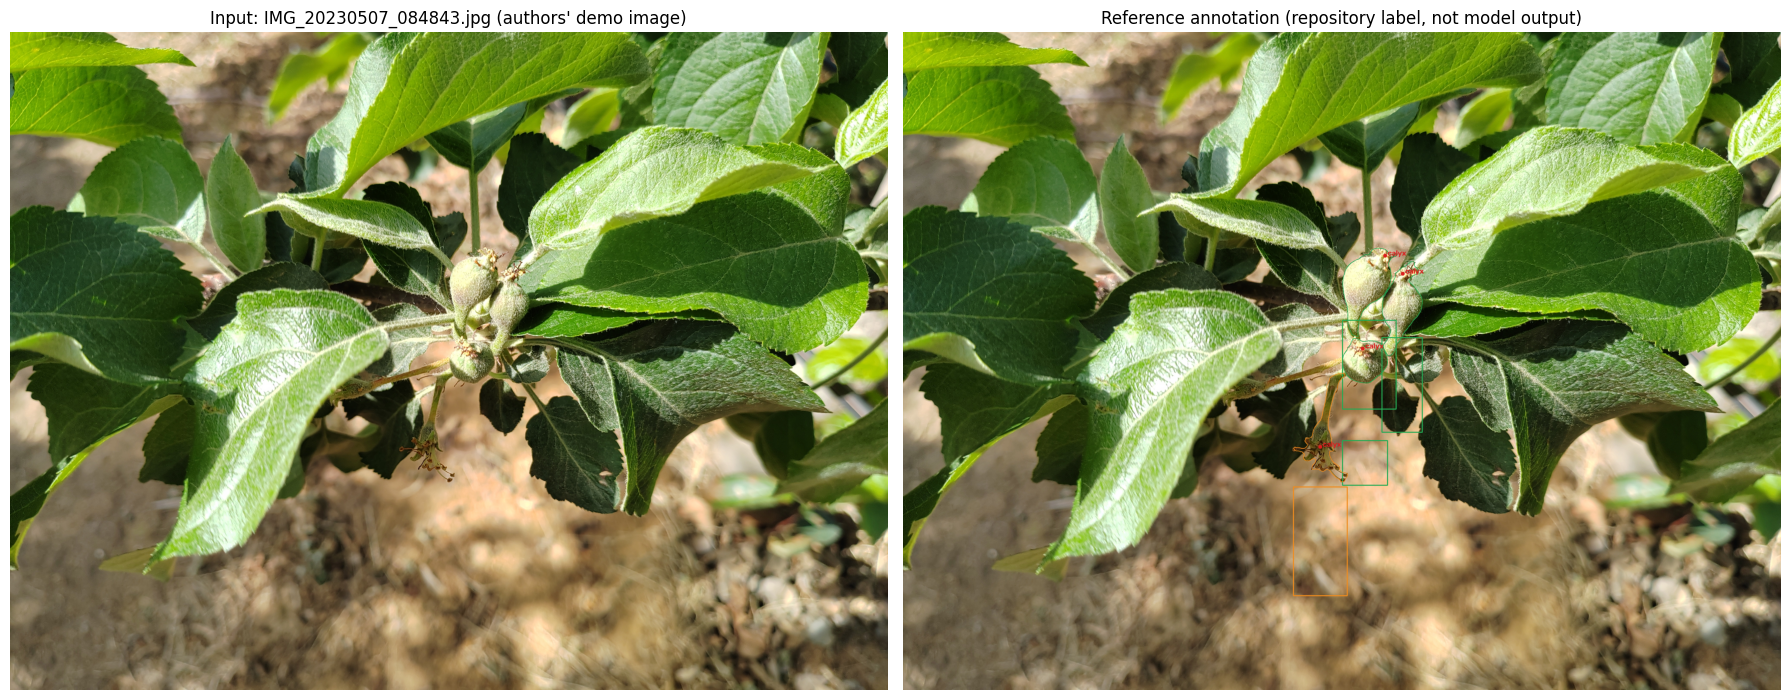

Saved: /content/input_vs_reference_annotation.png


In [ ]:
import cv2
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

CLASS_NAMES = {0: "green_fruit", 1: "flower"}
GT_COLORS = {0: (36, 170, 84), 1: (240, 140, 30)}  # RGB

img_bgr = cv2.imread(str(REPO_ROOT / "IMG_20230507_084843.jpg"))
assert img_bgr is not None
H, W = img_bgr.shape[:2]
print(f"Input image: {W}x{H} px, {W*H/1e6:.1f} MP")

def load_reference_labels(path, W, H):
    records = []
    for ln, line in enumerate(path.read_text().strip().splitlines(), 1):
        f = line.split()
        assert len(f) >= 9 and (len(f) - 8) % 2 == 0, f"label line {ln} does not match README format: {line[:120]}"
        cls = int(f[0]); x_c, y_c, w, h = map(float, f[1:5])
        kx, ky, vis = float(f[5]), float(f[6]), int(float(f[7]))
        seg = np.array(list(map(float, f[8:])), dtype=float).reshape(-1, 2) * [W, H]
        records.append(dict(cls=cls,
                            box=(int((x_c - w/2)*W), int((y_c - h/2)*W), int(w*W), int(h*H)),
                            kpt=(kx*W, ky*H, vis), segment=seg))
    return records

gt = load_reference_labels(REPO_ROOT / "ultralytics/data/labels/test/IMG_20230507_084843.txt", W, H)
print(f"Reference annotation: {len(gt)} instances "
      f"({sum(r['cls']==0 for r in gt)} green_fruit, {sum(r['cls']==1 for r in gt)} flower)")

gt_overlay = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).copy()
for r in gt:
    x, y, w, h = r["box"]
    c = GT_COLORS.get(r["cls"], (200, 200, 200))
    cv2.rectangle(gt_overlay, (x, y), (x + w, y + h), c, 4)
    if len(r["segment"]) >= 3:
        cv2.polylines(gt_overlay, [r["segment"].astype(np.int32)], True, c, 2)
    kx, ky, vis = r["kpt"]
    if vis > 0:
        cv2.circle(gt_overlay, (int(kx), int(ky)), 9, (220, 30, 30), -1)
        cv2.putText(gt_overlay, f"calyx", (int(kx) + 12, int(ky)), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (220, 30, 30), 2)

fig, axes = plt.subplots(1, 2, figsize=(18, 9))
axes[0].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)); axes[0].set_title("Input: IMG_20230507_084843.jpg (authors' demo image)", fontsize=12)
axes[1].imshow(gt_overlay); axes[1].set_title("Reference annotation (repository label, not model output)", fontsize=12)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("/content/input_vs_reference_annotation.png", dpi=90, bbox_inches="tight")
plt.show()
print("Saved: /content/input_vs_reference_annotation.png")

### Run the released model exactly as the authors' `demo.py` does
`demo.py` line 7–9: `YOLO(".../best.pt")` then `model.predict(img_path, retina_masks=True)[0]`. We keep the same
call with default confidence/IoU thresholds and `retina_masks=True` (native-resolution masks), only replacing the
authors' hardcoded Windows paths. We print the returned structure summary (counts, names, tensor shapes) —
no weights are dumped.

著者の `demo.py` と同一の呼び出し（`retina_masks=True`、既定の閾値）で推論します。著者の Windows パスを
`/content` に置き換えた点のみが変更です。結果の概要（件数・クラス名・形状）のみを表示します。

In [ ]:
model = YOLO(str(WEIGHTS))
model.to(DEVICE)

result = model.predict(str(REPO_ROOT / "IMG_20230507_084843.jpg"), retina_masks=True)[0]

n_det = 0 if result.boxes is None else len(result.boxes)
print("Instances detected:", n_det)
print("names:", result.names)
if n_det:
    print("conf range: %.3f–%.3f" % (float(result.boxes.conf.min()), float(result.boxes.conf.max())))
    print("masks:", type(result.masks).__name__, "xy polygons:", len(result.masks.xy))
    print("keypoints tensor:", tuple(result.keypoints.data.shape) if result.keypoints is not None else None)
assert n_det > 0, "No detections — the released best.pt must segment immature apples in the authors' demo image."

image 1/1 /content/YOLOv9s-Multi/IMG_20230507_084843.jpg: 480x640 3 green_fruits, 1 flower, 1279.5ms


Speed: 8.5ms preprocess, 1279.5ms inference, 794.5ms postprocess per image at shape (1, 3, 480, 640)


Instances detected: 4
names: {0: 'green_fruit', 1: 'flower'}
conf range: 0.789–0.847
masks: Masks xy polygons: 4
keypoints tensor: (4, 1, 3)


### Reproduce the authors' demo visualization (`demo.py` lines 11–36)
The authors draw, per detection: a bounding box + `class name conf` text, a red filled circle at the calyx
keypoint, and the segmentation mask blended over the image with `cv2.addWeighted(image, 1, mask, 0.7, 0)`. We copy
that logic verbatim, writing to `/content` instead of the authors' `C:/…/revise_r5/fig11/`.

著者の `demo.py`（11–36 行目）の描画処理（矩形＋クラス名+信頼度、萼キーポイントの赤丸、
`addWeighted` によるマスク重畳）をそのまま再現し、出力先を `/content` に変更します。

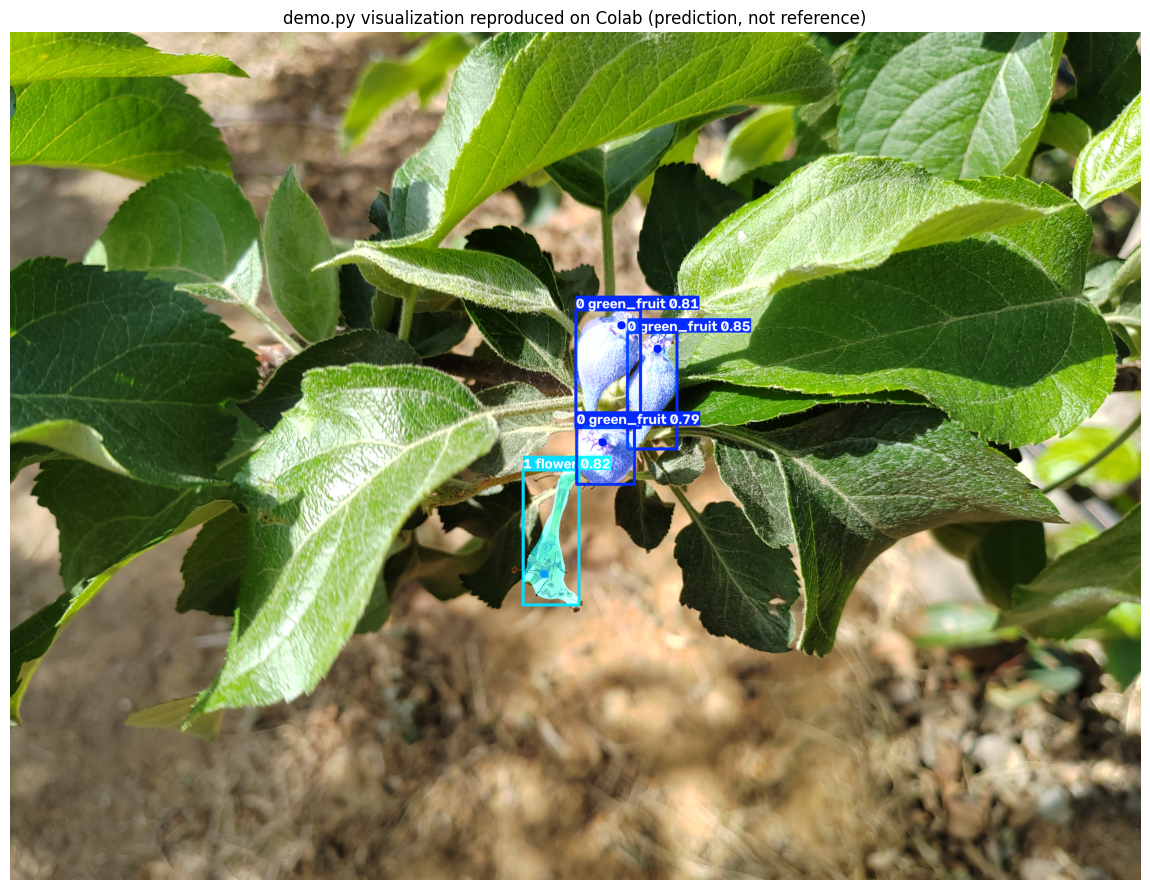

Saved: /content/demo_py_reproduction.png


In [ ]:
demo_viz = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).copy()

for xyxy, cls, conf, mask, keypoint, key_conf in zip(result.boxes.xyxy, result.boxes.cls, result.boxes.conf,
                                                     result.masks.xy, result.keypoints.xy, result.keypoints.conf):
    xyxy = xyxy.cpu().numpy()
    cls_id = int(cls.cpu().numpy())
    name = result.names[cls_id]
    conf_v = float(conf.cpu().numpy())
    x1, y1, x2, y2 = map(int, xyxy.tolist())
    # Authors' BGR palette: cls0 (255,42,4) red, cls1 (255,219,11) yellow, else (255,68,79)
    color_bgr = (255, 42, 4) if cls_id == 0 else (255, 219, 11) if cls_id == 1 else (255, 68, 79)
    color = (color_bgr[2], color_bgr[1], color_bgr[0])
    cv2.rectangle(demo_viz, (x1, y1), (x2, y2), color, 10)
    text = f"{cls_id} {name} {conf_v:.2f}"
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 1.7, 5)
    cv2.rectangle(demo_viz, (x1, y1), (x1 + tw, y1 - th - 5), color, -1)
    cv2.putText(demo_viz, text, (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 1.7, (255, 255, 255), 2)
    kx, ky = map(int, keypoint[0].tolist())
    cv2.circle(demo_viz, (kx, ky), 15, (0, 0, 255), -1)
    zero_mask = np.zeros(demo_viz.shape, dtype=np.uint8)
    poly = mask.astype(np.int32)
    poly = np.clip(poly, (x1, y1), (x2, y2))
    cv2.fillPoly(zero_mask, [poly], color)
    demo_viz = cv2.addWeighted(demo_viz, 1, zero_mask, 0.7, 0)

plt.figure(figsize=(12, 9))
plt.imshow(demo_viz)
plt.title("demo.py visualization reproduced on Colab (prediction, not reference)", fontsize=12)
plt.axis("off")
plt.tight_layout()
plt.savefig("/content/demo_py_reproduction.png", dpi=90, bbox_inches="tight")
plt.show()
print("Saved: /content/demo_py_reproduction.png")

### Orientation estimation — pixel-based, from the paper's stated method (AI-implemented)
The paper derives each fruit's orientation **without 3D data**: the segmentation-mask centroid of the instance is
paired with the detected calyx keypoint, and the orientation is the direction of the centroid→calyx vector
(orientation phase of the study flow; abstract: "the orientation is derived from the segmentation centroid and
calyx keypoint, enabling pixel-based fruit selection"). Because the full text is not retrievable, the paper's
**fruit-selection keep/remove rule and its thresholds are unknown and are NOT implemented here** — this cell only
estimates and draws the orientation angle. The angle is reported modulo 180° because the centroid→calyx direction
has a 180° axis ambiguity; the calyx side is the physical "tip" reference. This cell is an AI implementation of
the described method, not author code.

論文の記述に基づき、セグメンテーション重心と萼キーポイントを結ぶ方向を方位（0–180°）として推定します。
全文が入手不能なため、論文中の**選果（残す/除去）規則と閾値は未知であり本notebookでは実装しません**。
このセルは論文記述に基づく AI 実装です（著者コードではありません）。

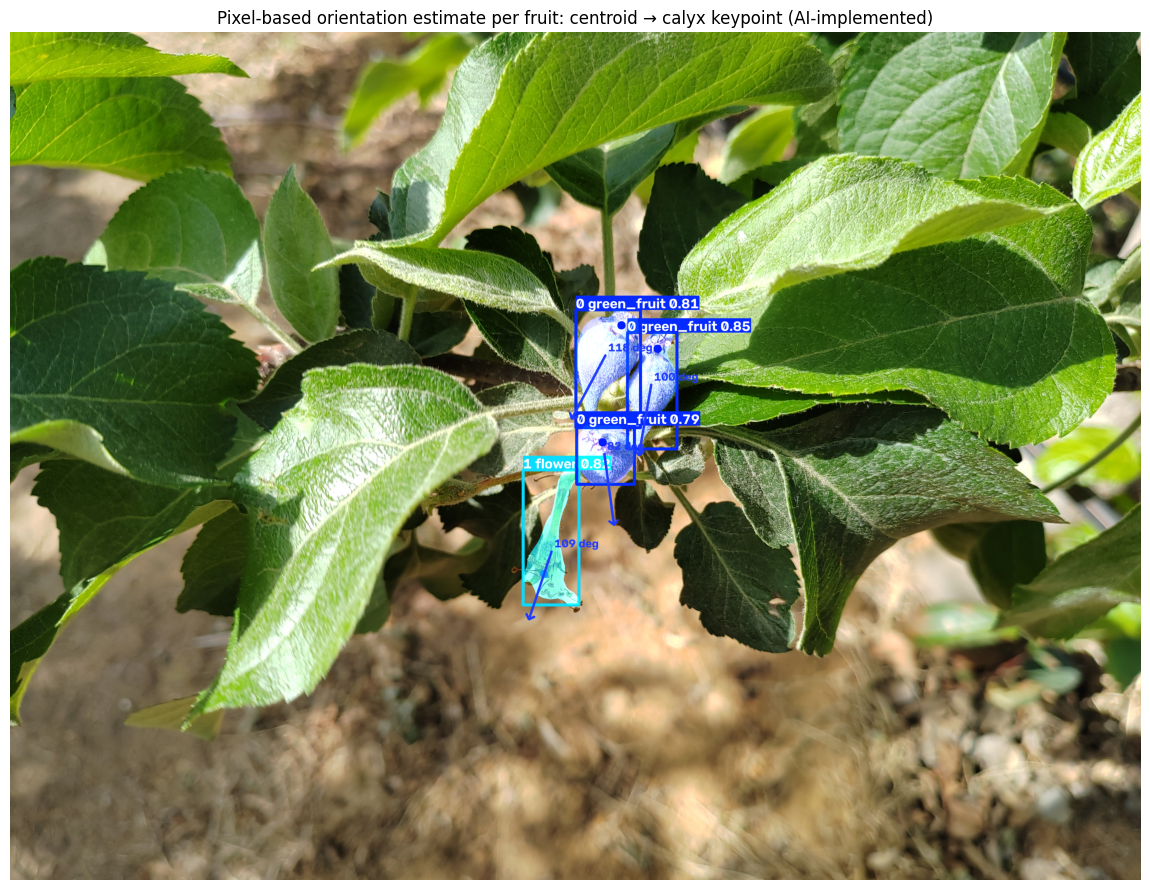

 instance  cls        name  conf  centroid_x_px  centroid_y_px  calyx_x_px  calyx_y_px  orientation_deg
        0    0 green_fruit 0.847         2322.1         1277.7      2345.1      1147.1            100.0
        1    1      flower 0.824         1962.0         1881.0      1934.4      1963.4            108.5
        2    0 green_fruit 0.810         2156.2         1171.2      2214.1      1062.0            117.9
        3    0 green_fruit 0.789         2152.3         1528.0      2146.7      1486.9             82.3
Saved: /content/orientation_estimates.png and /content/yolov9s_multi_orientation_results.csv


In [ ]:
def polygon_centroid(pts: np.ndarray) -> tuple:
    x, y = pts[:, 0], pts[:, 1]
    xn, yn = np.roll(x, -1), np.roll(y, -1)
    cross = x * yn - xn * y
    area = cross.sum() / 2.0
    if abs(area) < 1e-9:
        return float(x.mean()), float(y.mean())
    cx = ((x + xn) * cross).sum() / (6.0 * area)
    cy = ((y + yn) * cross).sum() / (6.0 * area)
    return float(cx), float(cy)

rows = []
orient_viz = demo_viz.copy()
for i, (mask_xy, kpt_xy, cls, conf_v) in enumerate(zip(result.masks.xy, result.keypoints.xy,
                                                       result.boxes.cls.cpu().numpy(),
                                                       result.boxes.conf.cpu().numpy())):
    pts = np.asarray(mask_xy, dtype=float)
    cx, cy = polygon_centroid(pts)
    kx, ky = map(float, kpt_xy[0].tolist())
    ang = np.degrees(np.arctan2(ky - cy, kx - cx)) % 180.0
    dx, dy = np.cos(np.radians(ang)), np.sin(np.radians(ang))
    cv2.arrowedLine(orient_viz, (int(cx), int(cy)), (int(cx + 260 * dx), int(cy + 260 * dy)),
                    (30, 60, 255), 8, tipLength=0.08)
    cv2.putText(orient_viz, f"{ang:.0f} deg", (int(cx) + 10, int(cy) - 14), cv2.FONT_HERSHEY_SIMPLEX, 1.4, (30, 60, 255), 3)
    rows.append(dict(instance=i, cls=int(cls), name=result.names[int(cls)], conf=round(float(conf_v), 3),
                     centroid_x_px=round(cx, 1), centroid_y_px=round(cy, 1),
                     calyx_x_px=round(kx, 1), calyx_y_px=round(ky, 1), orientation_deg=round(ang, 1)))

plt.figure(figsize=(12, 9))
plt.imshow(orient_viz)
plt.title("Pixel-based orientation estimate per fruit: centroid → calyx keypoint (AI-implemented)", fontsize=12)
plt.axis("off")
plt.tight_layout()
plt.savefig("/content/orientation_estimates.png", dpi=90, bbox_inches="tight")
plt.show()

import pandas as pd
orient_df = pd.DataFrame(rows)
print(orient_df.to_string(index=False))
orient_df.to_csv("/content/yolov9s_multi_orientation_results.csv", index=False)
print("Saved: /content/orientation_estimates.png and /content/yolov9s_multi_orientation_results.csv")

### Prediction vs. reference annotation (calyx keypoint check)
For every reference instance in the authors' label we find the predicted instance of the same class whose calyx
keypoint is nearest, and report the pixel distance. This is a plausibility check on the released weights for this
single demo image — **not** a reproduction of the paper's dataset-level AP or the 92.80%/72.59% orientation
accuracies, which require the (8 GB) test set and the paper's evaluation protocol. Predicted vs reference
keypoints are drawn on separate panels so model output and reference annotation stay clearly labeled.

各正解インスタンスに対し同クラスで最も近い予測キーポイントとの距離（px）を算出します。これは単一デモ画像の
妥当性確認であり、論文のデータセット精度（AP・方位精度 92.80%/72.59%）の再現ではありません。

In [ ]:
import math

ref_rows = []
unmatched = 0
pred_kpts = [(float(k[0][0]), float(k[0][1])) for k in result.keypoints.xy.cpu().numpy()]
pred_cls = result.boxes.cls.cpu().numpy().astype(int)
for gi, g in enumerate(gt):
    gx, gy, _ = g["kpt"]
    cands = [(abs(pred_kpts[i][0] - gx) + abs(pred_kpts[i][1] - gy), i)
             for i in range(len(pred_kpts)) if pred_cls[i] == g["cls"]]
    if not cands:
        unmatched += 1
        ref_rows.append(dict(ref_instance=gi, ref_class=CLASS_NAMES[g["cls"]], matched_instance=None,
                             keypoint_dist_px=None))
        continue
    dist_sum, mi = min(cands)
    dist = math.hypot(pred_kpts[mi][0] - gx, pred_kpts[mi][1] - gy)
    ref_rows.append(dict(ref_instance=gi, ref_class=CLASS_NAMES[g["cls"]], matched_instance=mi,
                         keypoint_dist_px=round(dist, 1)))
cmp_df = pd.DataFrame(ref_rows)
print(cmp_df.to_string(index=False))
matched = cmp_df.dropna(subset=["keypoint_dist_px"])
if len(matched):
    print(f"\nKeypoint distance vs reference: median {matched['keypoint_dist_px'].median():.1f} px, "
          f"max {matched['keypoint_dist_px'].max():.1f} px over {len(matched)} matched of {len(gt)} reference instances"
          + (f" ({unmatched} unmatched)" if unmatched else ""))
cmp_df.to_csv("/content/pred_vs_reference_keypoints.csv", index=False)
print("Saved: /content/pred_vs_reference_keypoints.csv")

 ref_instance   ref_class  matched_instance  keypoint_dist_px
            0 green_fruit                 2              38.0
            1 green_fruit                 0              21.4
            2 green_fruit                 3               7.4
            3      flower                 1              28.0

Keypoint distance vs reference: median 24.7 px, max 38.0 px over 4 matched of 4 reference instances
Saved: /content/pred_vs_reference_keypoints.csv


## Results, interpretation, and validation record

**What this notebook executed / 本notebookで実行したこと**
- Loaded the authors' released `best.pt` (16,492,055 B, Drive file ID `1mcJhXHlcaHPI6UWYtGcTfyltem0GPW_d`) with
  the authors' pinned Ultralytics fork (commit `2d86f561…`) and ran single-image inference on their demo image
  with `retina_masks=True` — the same call as `demo.py`.
- Reproduced the authors' box/mask/keypoint visualization, estimated per-fruit orientation from the segmentation
  centroid → calyx keypoint vector (paper method, AI-implemented), and compared predicted calyx keypoints with
  the repository's reference annotation.

**Interpretation / 解釈**
- A successful run shows immature-apple instances segmented at native resolution with a calyx keypoint per fruit,
  from which the pixel-based orientation follows without any 3D input — the core of the paper's approach.
- Orientation angles from this one image are a demonstration of the method, not a validation of the paper's
  reported orientation accuracy (92.80% FV-Stage / 72.59% FR-Stage within 30°) or selection accuracy
  (74.00% / 70.31%), which need the released test set and the paper's full protocol.

**Known limitations / 既知の制限**
1. The paper's fruit-selection keep/remove thresholds are unknown (full text not retrievable), so no selection
   decision is made. / 論文の選果閾値は未知のため、選果判定は行いません。
2. Single image; no dataset-level claims. / 単一画像のみでありデータセット精度は主張しません。
3. The orientation cell is AI-implemented from the paper description; the authors' exact implementation of this
   step was not published in the repository. / 方位推定は論文記述に基づく AI 実装です。
4. The authors' README notes the repository is still awaiting final figures ("waiting the final figures").

**Provenance / 出典:** paper DOI 10.1016/j.compag.2026.111664; code `DIANSLEE/YOLOv9s-Multi` @
`2d86f561cfe2bfc3e57e4b2dc48c6c0c5d2e7624` (Apache-2.0); weights & dataset from the authors' Google Drive folder
linked in the repository README. PhenoPaper investigation
`p-38822584108104d5d5e7b396d9598ee4-20260929T102859Z-2523563` was used as prior research guidance, not primary
proof.